In [1]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

###can also use dir() to check what is in function and that new params have been loaded

import os
import glob


desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
mypath = desktop
import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_data
from plots import plot_dsc, cummulative_plot

import data

In [2]:
from pathlib import Path
paths ={}
paths['3wk']={'path' : '//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables/'}
paths['5wk']={'path' : '//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/'}
paths['prox']={'path' : '//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140527_dg_proximal/tables/'}


STEDdata={}
for dataset, d in paths.items():
    #print('STEDdata'+'-'+dataset) 
    
    path_to_data=d['path']
    STEDdata[dataset]={}
    
    for File in glob.glob(path_to_data+"*Local*"):
        print(File)
        name = Path(File).name
        dendrite = 'dendrite'+name.split(' - ')[0]
        
        STEDdata[dataset][dendrite] = {'path':File} 
        STEDdata[dataset][dendrite]['file']= name
        STEDdata[dataset][dendrite]['ex_factor'] = 1
        STEDdata[dataset][dendrite]['res'] = 0.04


//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\16 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\17 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\21 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\25 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\25-2 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\27 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140412_3weeks_thy1_dg/tables\28 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/S

analyse each branch in the STED datasets

In [3]:
for n, dataSet in STEDdata.items():
    print(n)
    
    for name, dendrite in tqdm(dataSet.items()):
        #print(name)
        #print(data[name]['path'])
        
        file_path = dendrite['path']#+dendrite['file']
        dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

3wk


100%|██████████| 29/29 [00:04<00:00,  6.26it/s]


5wk


100%|██████████| 21/21 [00:02<00:00,  8.51it/s]


prox


100%|██████████| 15/15 [00:01<00:00,  7.66it/s]


manually adjust the results, erroneus DSCs removes and missed DSCs added

In [4]:
###3wks
#manually add/remove DSCs
branch = STEDdata['3wk']['dendrite25']
del branch['DSCs'][0]
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)


branch = STEDdata['3wk']['dendrite28']
#branch['DSCs'].pop[0] 
del branch['DSCs'][0]
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['3wk']['dendrite29-4']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['3wk']['dendrite39-21']
del branch['DSCs'][2]
update_DSCs(branch)
update_compartments(branch)


branch = STEDdata['3wk']['dendrite40-4'] #update DSC properties
DSC= branch['DSCs'][0]
branch['DSC_properties'][0]['mean'] = DSC.smth[37:47].mean()
branch['DSC_properties'][0]['length'] = DSC.length[DSC.length.index[0]+47]-DSC.length[DSC.length.index[0]+37]

branch = STEDdata['3wk']['dendrite41-0']
del branch['DSCs'][1]
update_DSCs(branch)
update_compartments(branch)

###5wks
#manually add/remove DSCs
branch = STEDdata['5wk']['dendrite36-2']
DSC=branch['data'][145:270].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite38-1'] #update DSC properties missing end upswing
DSC= branch['DSCs'][0]
branch['DSC_properties'][0]['mean'] = DSC.smth[11:32].mean()
branch['DSC_properties'][0]['length'] = DSC.length[DSC.length.index[0]+32]-DSC.length[DSC.length.index[0]+11]

#manually add/remove DSCs
branch = STEDdata['5wk']['dendrite42-2']
DSC=branch['data'][50:150].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite14']
del branch['DSCs'][3]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite43-1']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite43-2']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite55']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

plot the individual dendrites with each DSC highlited in a different colour

In [5]:
#plot_dsc(STEDdata['prox'])

get and plot summary stats
mean diameter and length of all DSCs across all dendrites

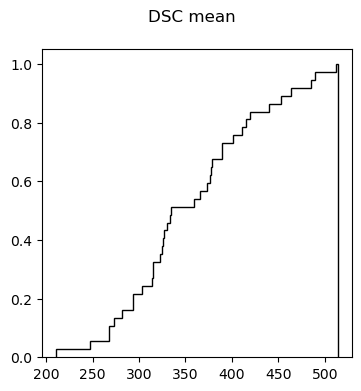

In [6]:
#select property to plot [mean, lenght]
parameter='mean'

df3= summary_data(STEDdata['3wk'], parameter)
#ax, fig = plot_stats(df3.transpose())
#fig.savefig('C:/Users/Tony Kelly/Desktop/DSC_mean.eps', bbox_inches = 'tight')
df5= summary_data(STEDdata['5wk'], parameter)
#ax, fig = plot_stats(df5.transpose())
#fig.savefig('C:/Users/Tony Kelly/Desktop/DSC_mean.eps', bbox_inches = 'tight')
dfProx= summary_data(STEDdata['prox'], parameter)

df = pd.concat([df3, df5])

fig, ax = plt.subplots(figsize=(4, 4))
n_bins=200
fig.suptitle('DSC '+parameter)
## plot the cumulative histogram for each branch
#n, bins, patches = ax.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)

#get average line for all branches 
df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='black', density=True, histtype='step', cumulative=True)
#ax.set_xlim([0,10])

fig.savefig('C:/Users/Tony Kelly/Desktop/DSC_Cumulative.svg', bbox_inches = 'tight')

In [7]:
print(df.mean())
print(df.sem())

357.13682565844795
11.829884172402393
